Compare active and idle states of IOT devices

Code structure: if possible have data and display independent, so that time can be saved by not recomputing unchanged data

e.g

```python
show_data(get_data())
```

rather than

```python
def show_data():
    get_data()
```

also increases configurability

Terms:

- Class
- Window (w seconds long)
- Shift (s seconds)


In [15]:
%load_ext autoreload
%autoreload 2
# function defs

from functools import partial
from util import *


def typst_table(
    df: pd.DataFrame, diag=True, left="s", right="w", style=lambda x: x, index_title=None, cell_transformer = None
):
    # if cell_transformer:
    #     df.map(lambda cell: f'tex')
    s = df.style.format(precision=3)
    s = style(s)

    
    string = s.to_typst().replace("\n", "")


    if diag:
        string = string.replace("[]", f"diagbox()[{left}][{right}]")
    elif index_title:
        string = string.replace("[]", f"[{index_title}]")
    display(string)
    display(s)

c = Context("../PowerIDS/classifier/power_csv")


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
# graph_confusion_matrix(exp, matrix)
# pp.pprint(list(zip(exp.devices, compute_f1_scores(matrix)))[::-1])
# Get a list of devices that are not correctly classified.
# pp.pprint(
#     {
#         Device: Counter(class_)
#         for Device, class_ in classes.items()
#         if len(Counter(class_).items()) > 1
#     }
# )
# TODO computer f1 score and do graph without those.

# TODO why is LIFX misclassified
# TODO would ordering this by median be easier?

plt.show()
window_sizes = [10, 60, 180, 300, 600]
shifts = [2, 10, 30, 60]

df = pd.DataFrame(
    [
        [
            Experiment(
                c,
                State.IDLE,
                [Metric.MEAN],
                Classifier.Median,
                window_size,
                shift,
            ).f1_macro_average
            for window_size in window_sizes
        ]
        for shift in shifts
    ],
    shifts,
    window_sizes,
)

Wrote graph to assets/confusion-matrix-idle-180-10-mean-Median.pdf


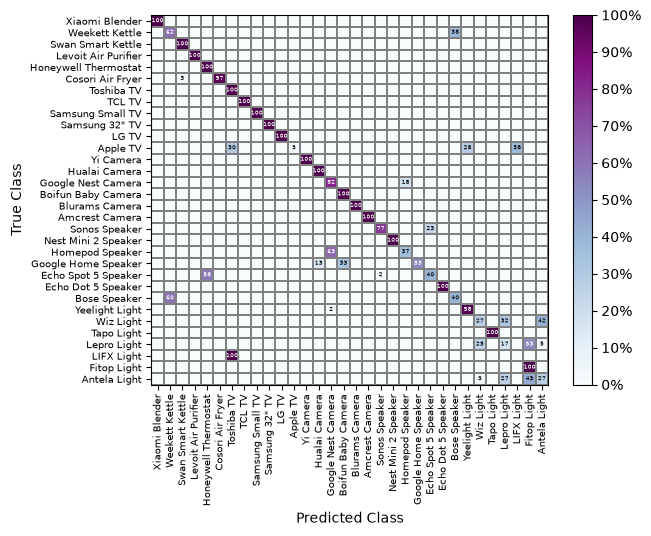

'#table(  columns: 3,  [IoT Device], [Precision], [F1 score],  [Antela Light], [nan], [nan],  [Fitop Light], [nan], [nan],  [LIFX Light], [nan], [nan],  [Lepro Light], [nan], [nan],  [Tapo Light], [nan], [nan],  [Wiz Light], [nan], [nan],  [Yeelight Light], [nan], [nan],  [Bose Speaker], [nan], [nan],  [Echo Dot 5 Speaker], [nan], [nan],  [Echo Spot 5 Speaker], [nan], [nan],  [Google Home Speaker], [nan], [nan],  [Homepod Speaker], [nan], [nan],  [Nest Mini 2 Speaker], [nan], [nan],  [Sonos Speaker], [nan], [nan],  [Amcrest Camera], [nan], [nan],  [Blurams Camera], [nan], [nan],  [Boifun Baby Camera], [nan], [nan],  [Google Nest Camera], [nan], [nan],  [Hualai Camera], [nan], [nan],  [Yi Camera], [nan], [nan],  [Apple TV], [nan], [nan],  [LG TV], [nan], [nan],  [Samsung 32" TV], [nan], [nan],  [Samsung Small TV], [nan], [nan],  [TCL TV], [nan], [nan],  [Toshiba TV], [nan], [nan],  [Cosori Air Fryer], [nan], [nan],  [Honeywell Thermostat], [nan], [nan],  [Levoit Air Purifier], [nan], [n

,Precision,F1 score
Antela Light,nan,nan
Fitop Light,nan,nan
LIFX Light,nan,nan
Lepro Light,nan,nan
Tapo Light,nan,nan
Wiz Light,nan,nan
Yeelight Light,nan,nan
Bose Speaker,nan,nan
Echo Dot 5 Speaker,nan,nan
Echo Spot 5 Speaker,nan,nan


Wrote graph to assets/confusion-matrix-idle-600-60-mean-Median.pdf


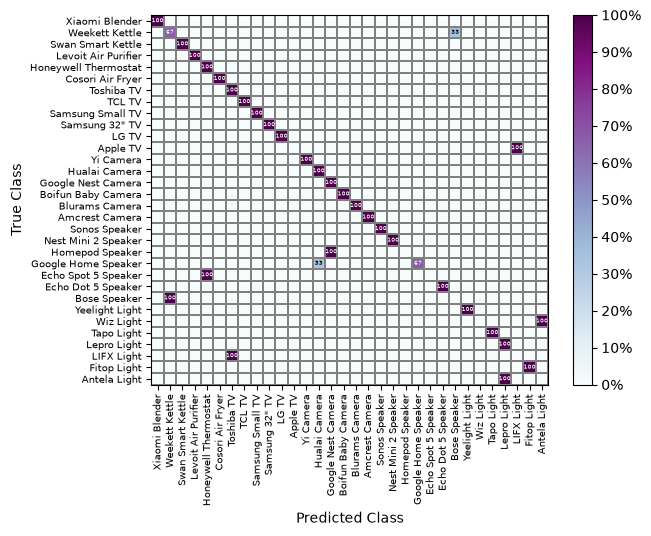

'#table(  columns: 3,  [IoT Device], [Precision], [F1 score],  [Device], [IoT Device], [IoT Device],  [Antela Light], [nan], [nan],  [Fitop Light], [nan], [nan],  [LIFX Light], [nan], [nan],  [Lepro Light], [nan], [nan],  [Tapo Light], [nan], [nan],  [Wiz Light], [nan], [nan],  [Yeelight Light], [nan], [nan],  [Bose Speaker], [nan], [nan],  [Echo Dot 5 Speaker], [nan], [nan],  [Echo Spot 5 Speaker], [nan], [nan],  [Google Home Speaker], [nan], [nan],  [Homepod Speaker], [nan], [nan],  [Nest Mini 2 Speaker], [nan], [nan],  [Sonos Speaker], [nan], [nan],  [Amcrest Camera], [nan], [nan],  [Blurams Camera], [nan], [nan],  [Boifun Baby Camera], [nan], [nan],  [Google Nest Camera], [nan], [nan],  [Hualai Camera], [nan], [nan],  [Yi Camera], [nan], [nan],  [Apple TV], [nan], [nan],  [LG TV], [nan], [nan],  [Samsung 32" TV], [nan], [nan],  [Samsung Small TV], [nan], [nan],  [TCL TV], [nan], [nan],  [Toshiba TV], [nan], [nan],  [Cosori Air Fryer], [nan], [nan],  [Honeywell Thermostat], [nan], [

,Precision,F1 score
Device,,
Antela Light,nan,nan
Fitop Light,nan,nan
LIFX Light,nan,nan
Lepro Light,nan,nan
Tapo Light,nan,nan
Wiz Light,nan,nan
Yeelight Light,nan,nan
Bose Speaker,nan,nan
Echo Dot 5 Speaker,nan,nan


Wrote graph to assets/confusion-matrix-active-180-10-mean-Median.pdf


'#table(  columns: 2,  [State], [Macro Average F1 score],  [Idle], [0.743],  [Average], [0.834],)'

,Macro Average F1 score
Idle,0.743
Average,0.834


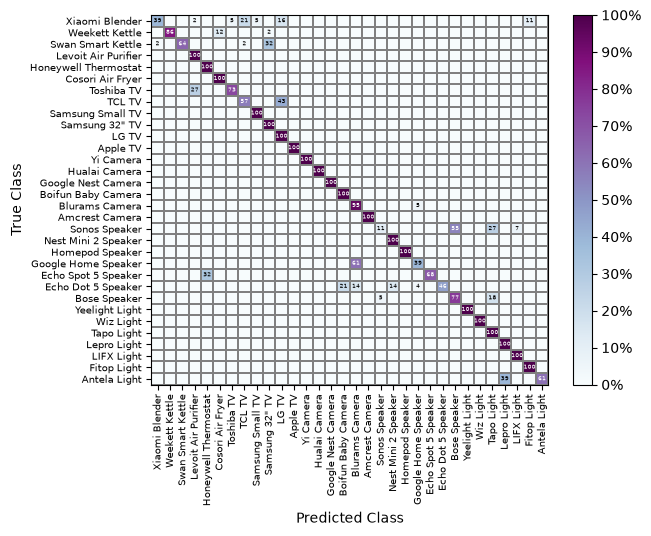

In [9]:
# | label: confusion matrix
idle = Experiment(
    c,
    [State.IDLE],
    [Metric.MEAN],
    Classifier.Median,
    180,
    10,
)
graph_confusion_matrix(idle)
plt.show()

typst_table(
    # pd.DataFrame.from_dict(
    #     sort_dict_by_value(all.f1_scores, reverse=True), orient="index"
    # ),
    pd.DataFrame(
        data={"Precision": idle.precision, "F1 score": idle.f1_scores},
        index=idle.devices,
    ).sort_values(by=["Precision"], ascending=False),
    diag=False,
    index_title="IoT Device",
)

out = Experiment(
    c,
    [State.IDLE],
    [Metric.MEAN],
    Classifier.Median,
    600,
    60,
)
graph_confusion_matrix(out)
plt.show()

performance = pd.DataFrame(
    data={"Precision": idle.precision, "F1 score": idle.f1_scores}, index=idle.devices
).sort_values(by=["Precision"], ascending=False)
performance.index.name = "Device"
typst_table(
    # pd.DataFrame.from_dict(
    #     sort_dict_by_value(all.f1_scores, reverse=True), orient="index"
    # ),
    performance,
    diag=False,
    index_title="IoT Device",
)


# display(len([1 for score in all.f1_scores.values() if score > 0.9]))

# # include only devices from above who are not equal to 100
active = Experiment(
    c,
    [State.ACTIVE],
    [Metric.MEAN],
    Classifier.Median,
    180,
    10,
)
graph_confusion_matrix(active)

typst_table(
    pd.DataFrame(
        data={
            "Macro Average F1 score": [idle.f1_macro_average, active.f1_macro_average]
        },
        index=["Idle", "Average"],
    ),
    diag=False,
    index_title="State",
)

In [ ]:
# | label: confused with

# for a device, see what other devices it is confused with
# [ for device, class_ in all.classes.items() if class]


# lifx = all.devices[2]
# 1 function for getting data either training or otherwise to plot.

# 1 function to actually plot it
def confused_with(exp, device: Device):
    # return training datums that are confused with the device, and the devices training and testing.

def plot_metrics(exp: Experiment, data: list[Datum], log_scale=False):
    """
   data is specifed in the form of (str, Data)
    """
    if len(exp.metrics) > 1:
        raise ValueError

    fig, ax = plt.subplots()


    for datum in data:
        training = compute_profile(exp, datum.training)
        if datum.device in show_testing
    if device_name:
        main_device = [
            device for device in exp.devices if device.dir_name == device_name
        ][0]
        main_data = [data for data in exp.data if data.device.dir_name == device_name][
            0
        ]
        
        if main_device not in devices:
            devices = [main_device] + devices

        # testing = compute_profile(exp, main_data.testing)
        # for point in testing:
        #     ax.scatter(
        #         point[exp.metrics[0]], len(devices), c=main_device.colour, marker="."
        #     )
    else:
        devices = exp.devices
    indexes = [exp.devices.index(device) for device in devices]
    n = len(devices)

    for i, (index, device) in enumerate(zip(indexes, devices)):
        data = exp.data[index]

        # plot the training
        points = []
        for point in training:
            actual_point = point[exp.metrics[0]]
            ax.scatter(actual_point, n - i - 1, c=device.colour, marker=".")
            points.append(actual_point)
        ax.scatter(np.median(points), n - i - 1, marker="|", s=200, c=device.colour)

        # ax.scatter(point, 1, marker=".")
    if log_scale:
        ax.set_xscale("log")

    ax.set_ylim((-1, n + 1))
    ax.set_yticks(
        range(n + 1),
        labels=[f"{device.name()} {"Model"}" for device in devices[::-1]]
        + [f"{main_device.name()} Testing"],
    )

    ax.set_xlabel("Power (W)")
    fig.set_figheight(n / 2)


plot_confusion(idle, "lifx")
plot_confusion(idle, "weekett")
plot_confusion(idle, "appletv")
plot_confusion(active, "lifx")
plot_confusion(active, "weekett")
plot_confusion(active, "weekett", log_scale=True)
plot_confusion(active, "appletv")
plot_confusion(active, log_scale=True)
# TODO mode to plot overlapping distributions
# TODO randomly selected windows, are there startup effects?
plt.show()

IndentationError: expected an indented block after function definition on line 11 (2669742548.py, line 14)

Wrote graph to assets/confusion-matrix-idle-300-120-mean-std-Median.pdf
0.8123556998556998
Wrote graph to assets/confusion-matrix-active-300-120-mean-std-Median.pdf
0.9031746031746033


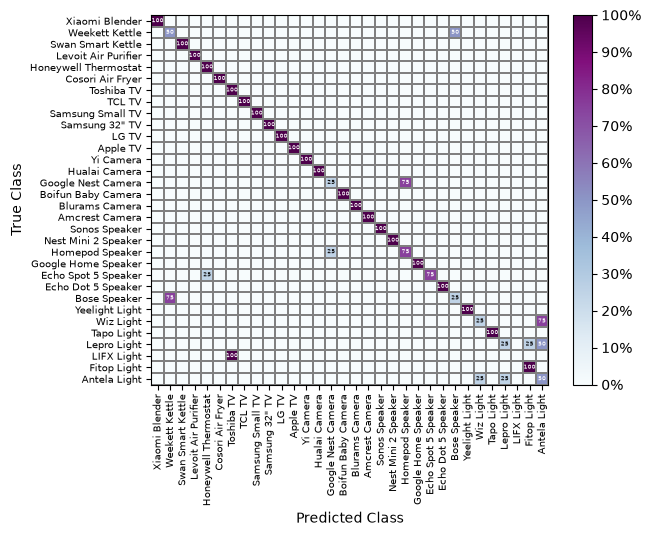

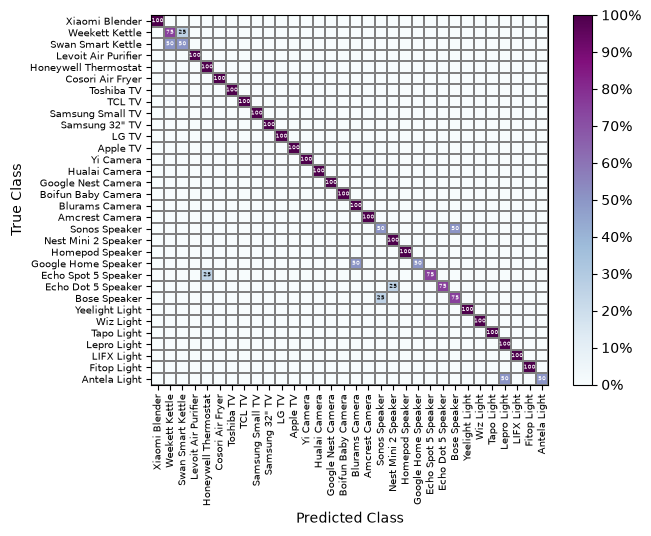

In [ ]:
# | label: mu sigma

mu_sigma = Experiment(
    c,
    [State.IDLE],
    [Metric.MEAN, Metric.STD],
    Classifier.Median,
    300,
    120,
)

graph_confusion_matrix(mu_sigma)
print(mu_sigma.f1_macro_average)

mu_sigma = Experiment(
    c,
    [State.ACTIVE],
    [Metric.MEAN, Metric.STD],
    Classifier.Median,
    300,
    120,
)

graph_confusion_matrix(mu_sigma)
print(mu_sigma.f1_macro_average)

Wrote graph to assets/confusion-matrix-idle-300-120-fft-Median.pdf
Wrote graph to assets/confusion-matrix-active-300-120-mean-fft-Median.pdf


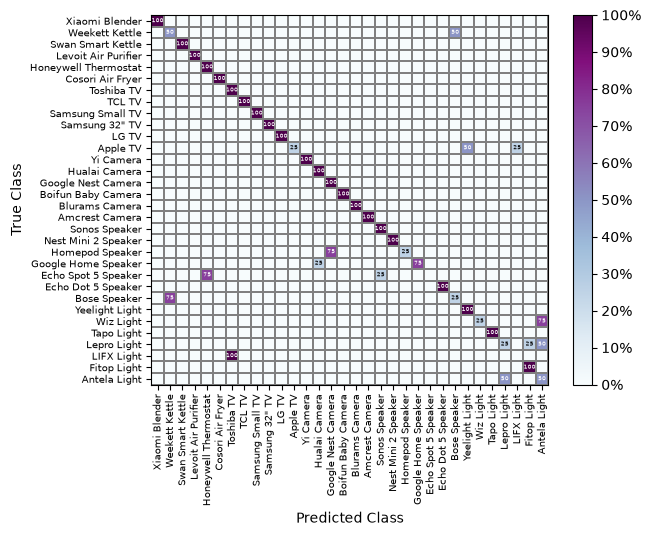

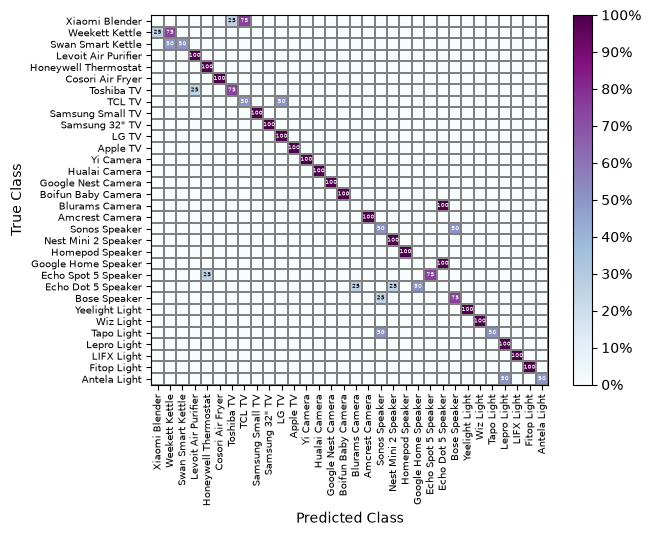

In [ ]:
# | label: fft

fft = Experiment(
    c,
    State.IDLE,
    [Metric.FFT],
    Classifier.Median,
    300,
    120,
)

graph_confusion_matrix(fft)

fft_both = Experiment(
    c,
    State.ACTIVE,
    [Metric.MEAN, Metric.FFT],
    Classifier.Median,
    300,
    120,
)

graph_confusion_matrix(fft_both)

Finished line s = 10
Finished line s = 50
Finished line s = 100


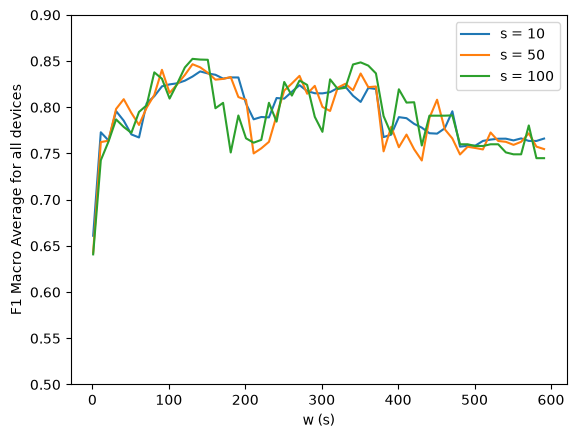

Finished line s = 10
Finished line s = 50
Finished line s = 100


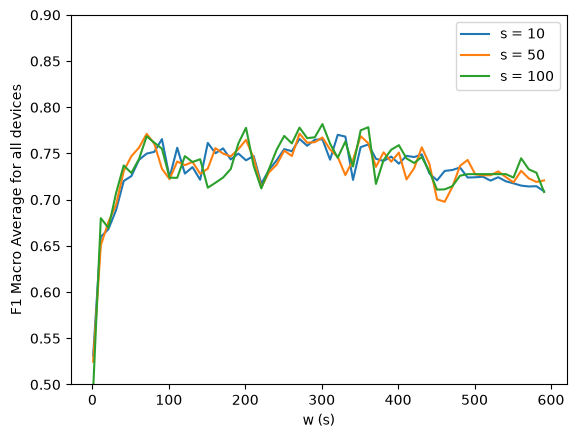

In [ ]:
# | label: fix_w_and_s

common = partial(
    Experiment,
    c,
    metrics=[Metric.MEAN],
    classify_by=Classifier.Median,
)

resolution = 10
for state in State:
    fig, ax = plt.subplots()
    fig.subplots_adjust(hspace=0.05)  # adjust space between Axes

    ws = np.arange(1, 601, resolution)
    for s in [10, 50, 100]:
        ys = [common(states=[state], w=int(w), s=s).f1_macro_average for w in ws]
        ax.plot(
            ws,
            ys,
            label=f"s = {s}",
        )

        print(f"Finished line s = {s}")
    ax.set_ylim(0.5, 0.9)
    ax.set_xlabel("w (s)")
    ax.set_ylabel("F1 Macro Average for all devices")
    ax.legend()
    plt.show()
    fig.savefig(f"assets/w_s_{state}_{resolution}.pdf")

In [18]:
# | label: info

w = 150
s = 100

exp = Experiment(
    c,
    [State.IDLE],
    [Metric.MEAN],
    Classifier.Median,
    w,
    s,
    # include=["cosori", "appletv", "tcltv", "toshiba"],
)
print(len(exp.devices))
print(c.categories)
print(len(exp.data[0].testing.df))

32
['lights', 'audio', 'camera', 'tv', 'appliance']
778


In [19]:
# | label: summary


get_scores = lambda exp: list(exp.f1_scores.values()) + [exp.f1_macro_average]

common = partial(Experiment, c, classify_by=Classifier.Median, w=w, s=s)

summary_idle_mean = common([State.IDLE], [Metric.MEAN])

summary_active_mean = common([State.ACTIVE], [Metric.MEAN])

summary_idle_mean_std = common([State.IDLE], [Metric.MEAN, Metric.STD])

summary_active_mean_std = common([State.ACTIVE], [Metric.MEAN, Metric.STD])
mean_fancy = Metric.MEAN.fancy_name()
std_fancy = Metric.STD.fancy_name()

scores = pd.DataFrame(
    data={
        f"Idle by {mean_fancy}": summary_idle_mean.f1_scores,
        f"Idle by {mean_fancy}, {std_fancy}": summary_idle_mean_std.f1_scores,
        f"Active by {mean_fancy}": summary_active_mean.f1_scores,
        f"Active by {mean_fancy}, {std_fancy}": summary_active_mean_std.f1_scores,
    },
    index=exp.devices + ["Macro Average"],
).sort_values(by=f"Idle by {mean_fancy}", ascending=False)

scores.loc["Macro Average"] = [
    summary_idle_mean.f1_macro_average,
    summary_idle_mean_std.f1_macro_average,
    summary_active_mean.f1_macro_average,
    summary_active_mean_std.f1_macro_average,
]
typst_table(
    scores,
    diag=False,
    index_title="Device",
)

'#table(  columns: 5,  [Device], [Idle by μ], [Idle by μ, σ], [Active by μ], [Active by μ, σ],  [Antela Light], [nan], [nan], [nan], [nan],  [Fitop Light], [nan], [nan], [nan], [nan],  [LIFX Light], [nan], [nan], [nan], [nan],  [Lepro Light], [nan], [nan], [nan], [nan],  [Tapo Light], [nan], [nan], [nan], [nan],  [Wiz Light], [nan], [nan], [nan], [nan],  [Yeelight Light], [nan], [nan], [nan], [nan],  [Bose Speaker], [nan], [nan], [nan], [nan],  [Echo Dot 5 Speaker], [nan], [nan], [nan], [nan],  [Echo Spot 5 Speaker], [nan], [nan], [nan], [nan],  [Google Home Speaker], [nan], [nan], [nan], [nan],  [Homepod Speaker], [nan], [nan], [nan], [nan],  [Nest Mini 2 Speaker], [nan], [nan], [nan], [nan],  [Sonos Speaker], [nan], [nan], [nan], [nan],  [Amcrest Camera], [nan], [nan], [nan], [nan],  [Blurams Camera], [nan], [nan], [nan], [nan],  [Boifun Baby Camera], [nan], [nan], [nan], [nan],  [Google Nest Camera], [nan], [nan], [nan], [nan],  [Hualai Camera], [nan], [nan], [nan], [nan],  [Yi Came

,Idle by μ,"Idle by μ, σ",Active by μ,"Active by μ, σ"
Antela Light,nan,nan,nan,nan
Fitop Light,nan,nan,nan,nan
LIFX Light,nan,nan,nan,nan
Lepro Light,nan,nan,nan,nan
Tapo Light,nan,nan,nan,nan
Wiz Light,nan,nan,nan,nan
Yeelight Light,nan,nan,nan,nan
Bose Speaker,nan,nan,nan,nan
Echo Dot 5 Speaker,nan,nan,nan,nan
Echo Spot 5 Speaker,nan,nan,nan,nan


/home/jack/Documents/Subjects/thesis/notebooks/util.py:527: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  


Wrote graph to assets/confusion-matrix-idle-active-300-10-mean-Median.pdf


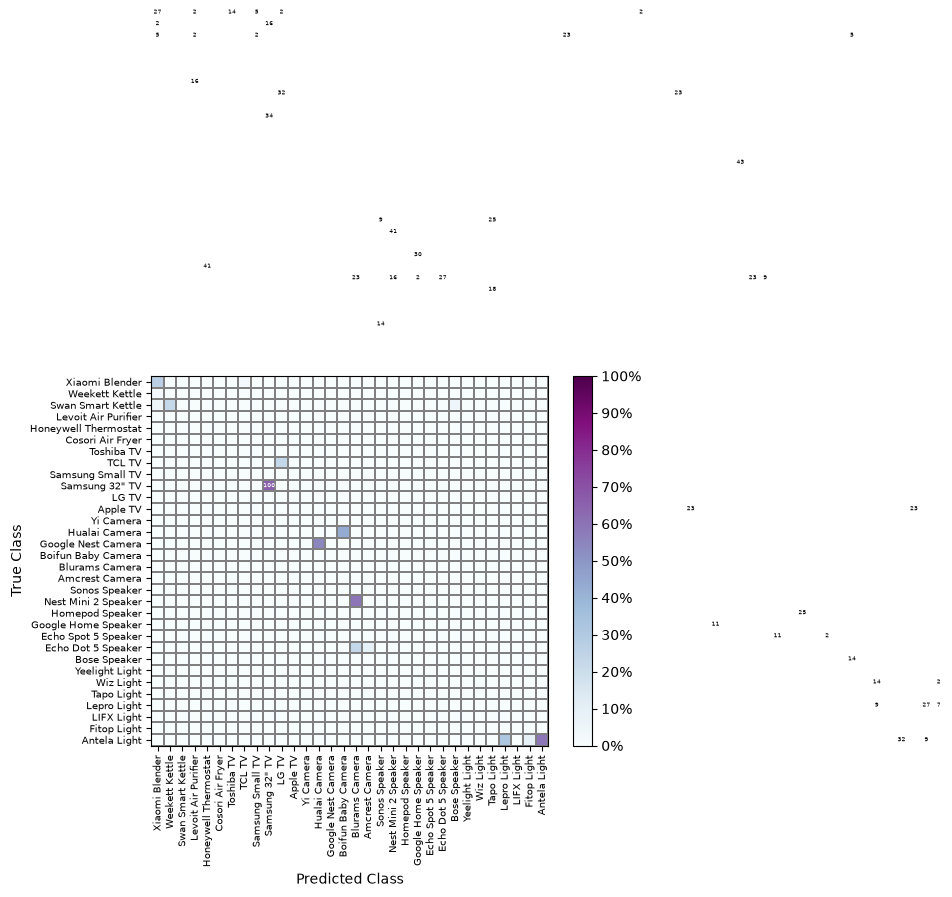

In [ ]:
# | label: combined

both = Experiment(
    c,
    states=[state.IDLE, state.ACTIVE],
    metrics=[Metric.MEAN],
    classify_by=Classifier.Median,
    w=300,
    s=10,
)
both.f1_macro_average
len(both.data)
graph_confusion_matrix(both)